# TP 1 (NLP) - Construire un pipeline de machine learning

**Cours NLP et Transformers - CY Tech**

Pipeline complet de classification de texte, de bout en bout :

`texte brut -> pretraitement -> representation -> modele -> mesure`

Le but n'est pas le meilleur score, mais que chaque decision soit justifiee et
que le score annonce soit credible.

**Les deux erreurs qui coutent des points :**
- Vectoriser avant de decouper train / test (fuite de donnees).
- Afficher une matrice de confusion sans la commenter.

In [1]:
import re
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Charger le corpus

Le corpus Tiny Shakespeare : du texte brut, sans aucune etiquette. Une grande
partie du travail consiste a transformer cette matiere brute en un probleme
d'apprentissage bien pose.

In [2]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
texte = urllib.request.urlopen(url).read().decode("utf-8")

print(len(texte), "caracteres")
print(len(texte.splitlines()), "lignes")
print(texte[:300])

1115394 caracteres
40000 lignes
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## 2. Observer la structure avant de coder

Avant d'ecrire quoi que ce soit, on regarde les donnees.

In [3]:
print(texte[1000:2500])

Second Citizen:
Would you proceed especially against Caius Marcius?

All:
Against him first: he's a very dog to the commonalty.

Second Citizen:
Consider you what services he has done for his country?

First Citizen:
Very well; and could be content to give him good
report fort, but that he pays himself with being proud.

Second Citizen:
Nay, but speak not maliciously.

First Citizen:
I say unto you, what he hath done famously, he did
it to that end: though soft-conscienced men can be
content to say it was for his country he did it to
please his mother and to be partly proud; which he
is, even till the altitude of his virtue.

Second Citizen:
What he cannot help in his nature, you account a
vice in him. You must in no way say he is covetous.

First Citizen:
If I must not, I need not be barren of accusations;
he hath faults, with surplus, to tire in repetition.
What shouts are these? The other side o' the city
is risen: why stay we prating here? to the Capitol!

All:
Come, come.

First C

**Reponses :**

1. Le texte alterne un nom de locuteur en majuscules suivi de deux points, puis
   sa replique. Les blocs sont separes par une ligne vide.
2. Le nom du locuteur peut servir d'etiquette : on peut predire qui parle.
3. Cette etiquette existe deja dans le texte, aucun annotateur humain n'est
   necessaire. C'est le principe de l'apprentissage auto-supervise.

## 3. Construire le jeu de donnees etiquete

La fonction de parsing est donnee. On la lit quand meme pour justifier ce
qu'elle garde et ce qu'elle jette.

In [4]:
def parser_repliques(txt):
    # Decoupe le corpus en repliques (locuteur, replique).
    # Format attendu : une ligne "NOM:" puis une ou plusieurs lignes de texte,
    # les blocs etant separes par une ligne vide.
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)

print(len(df), "repliques extraites")
print(df["locuteur"].nunique(), "locuteurs distincts")
df.head()

7094 repliques extraites
297 locuteurs distincts


,locuteur,replique
0,First Citizen,"Before we proceed any further, hear me speak."
1,All,"Speak, speak."
2,First Citizen,You are all resolved rather to die than to fam...
3,All,Resolved. resolved.
4,First Citizen,"First, you know Caius Marcius is chief enemy t..."


### 3.1 Explorer la distribution

locuteur
GLOUCESTER           211
DUKE VINCENTIO       189
MENENIUS             161
ROMEO                160
PETRUCHIO            155
CORIOLANUS           148
KING RICHARD III     137
ISABELLA             127
LEONTES              124
JULIET               124
SICINIUS             117
KING EDWARD IV       109
QUEEN ELIZABETH      105
LUCIO                101
WARWICK               98
KING RICHARD II       98
BRUTUS                91
HENRY BOLINGBROKE     90
TRANIO                90
BUCKINGHAM            89
Name: count, dtype: int64
longueur mediane : 14.0
longueur moyenne : 27.2


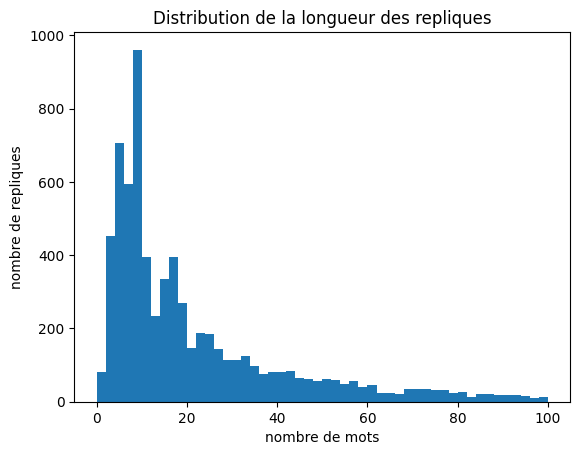

In [5]:
compte_locuteurs = df["locuteur"].value_counts()
print(compte_locuteurs.head(20))

longueurs = df["replique"].str.split().apply(len)
print("longueur mediane :", longueurs.median())
print("longueur moyenne :", round(longueurs.mean(), 1))

plt.hist(longueurs, bins=50, range=(0, 100))
plt.xlabel("nombre de mots")
plt.ylabel("nombre de repliques")
plt.title("Distribution de la longueur des repliques")
plt.show()

**Reponses :**

1. La distribution est tres desequilibree : quelques personnages parlent
   enormement, la majorite tres peu. Garder les 297 locuteurs donnerait des
   centaines de classes dont beaucoup avec une poignee d'exemples.
2. La longueur mediane est faible (quelques mots). C'est court pour de la
   classification de texte.
3. Des repliques courtes donnent des vecteurs TF-IDF tres creux, avec peu de
   mots informatifs par exemple.

## 4. Definir la tache

**Choix et justification :**
- Nombre de locuteurs retenus : 5 (les plus frequents), pour avoir des classes
  avec assez d'exemples et une accuracy qui a du sens.
- Seuil de longueur minimale : 12 mots, pour ecarter les repliques trop courtes
  qui ne portent presque aucun signal.

In [6]:
nombre_locuteurs = 5
longueur_minimale = 12

locuteurs_retenus = compte_locuteurs.head(nombre_locuteurs).index
donnees = df[df["locuteur"].isin(locuteurs_retenus)].copy()
donnees = donnees[donnees["replique"].str.split().apply(len) >= longueur_minimale]
donnees = donnees.reset_index(drop=True)

print(donnees["locuteur"].value_counts())
print(len(donnees), "exemples retenus")

locuteur
GLOUCESTER        119
DUKE VINCENTIO    113
MENENIUS          101
ROMEO              87
PETRUCHIO          83
Name: count, dtype: int64
503 exemples retenus


## 5. Decouper AVANT toute transformation

C'est le point le plus important : tout composant qui apprend quelque chose
(vocabulaire, poids IDF) doit etre ajuste sur le train seulement. On stratifie
pour qu'aucun locuteur ne manque dans le test.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    donnees["replique"],
    donnees["locuteur"],
    test_size=0.2,
    stratify=donnees["locuteur"],
    random_state=RANDOM_STATE,
)

print(len(X_train), "exemples train")
print(len(X_test), "exemples test")

402 exemples train
101 exemples test


## 6. Representer le texte (TF-IDF)

**Choix et justification :**
- `lowercase=True` : la casse n'identifie pas le style d'un personnage.
- `ngram_range=(1, 2)` : les bigrammes recuperent un peu d'ordre local.
- `min_df=2` : un mot vu une seule fois n'est pas fiable.
- `max_df=0.9` : on ecarte les mots quasi omnipresents.
- `stop_words` : on NE retire PAS les stopwords. Les mots fonctionnels portent
  le style propre a chaque locuteur (piege vu en cours).
- `sublinear_tf=True` : 10 occurrences ne valent pas 10 fois 1 occurrence.

In [8]:
vectoriseur = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9,
    sublinear_tf=True,
)

Xtr = vectoriseur.fit_transform(X_train)
Xte = vectoriseur.transform(X_test)

print("taille du vocabulaire :", len(vectoriseur.vocabulary_))
print("matrice train :", Xtr.shape)
print("sparsite :", round(Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1]) * 100, 3), "% non nuls")

taille du vocabulaire : 3072
matrice train : (402, 3072)
sparsite : 1.427 % non nuls


**Reponses :**

1. La quasi totalite de la matrice est faite de zeros : chaque replique ne
   contient qu'une petite fraction du vocabulaire global.
2. Une matrice dense occuperait une memoire enorme et inutile ; la
   representation creuse ne stocke que les valeurs non nulles.
3. Les IDF les plus faibles sont des mots tres courants, les plus eleves des
   mots rares et specifiques.

In [9]:
termes = vectoriseur.get_feature_names_out()
ordre = np.argsort(vectoriseur.idf_)

print("IDF le plus faible (mots frequents) :")
print(termes[ordre[:15]].tolist())
print("IDF le plus eleve (mots rares) :")
print(termes[ordre[-15:]].tolist())

IDF le plus faible (mots frequents) :
['and', 'the', 'to', 'of', 'you', 'that', 'is', 'in', 'not', 'my', 'with', 'for', 'me', 'this', 'it']
IDF le plus eleve (mots rares) :
['your business', 'your best', 'youngest', 'young edward', 'you you', 'afternoon', 'after dinner', 'afford', 'affect', 'afeard', 'advise him', 'advice', 'adieu', 'action', 'acquainted with']


## 7. Modeliser

### 7.1 D'abord la baseline

La baseline donne le plancher : le score atteint sans rien apprendre.

In [10]:
baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline.fit(Xtr, y_train)
pred_baseline = baseline.predict(Xte)

print("baseline most_frequent")
print("accuracy :", round(accuracy_score(y_test, pred_baseline), 3))
print("f1 macro :", round(f1_score(y_test, pred_baseline, average="macro"), 3))

baseline most_frequent
accuracy : 0.238
f1 macro : 0.077


### 7.2 Au moins deux modeles

On compare Naive Bayes, regression logistique et SVM lineaire. Ces trois
modeles sont adaptes a une representation creuse et de grande dimension.
On utilise `class_weight='balanced'` la ou c'est possible car les classes
sont desequilibrees.

In [11]:
modeles = {
    "Naive Bayes": MultinomialNB(),
    "Regression logistique": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "SVM lineaire": LinearSVC(class_weight="balanced"),
}

resultats = {}
for nom, modele in modeles.items():
    modele.fit(Xtr, y_train)
    resultats[nom] = modele.predict(Xte)

print("modeles entraines :", list(resultats.keys()))

modeles entraines : ['Naive Bayes', 'Regression logistique', 'SVM lineaire']


## 8. Evaluer et analyser

### 8.1 Les metriques

Sur des classes desequilibrees l'accuracy ment : on reporte aussi le F1 macro
(qui traite les classes a egalite) et le F1 weighted.

In [12]:
lignes = []
for nom, pred in resultats.items():
    lignes.append({
        "modele": nom,
        "accuracy": accuracy_score(y_test, pred),
        "precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "rappel_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_test, pred, average="weighted", zero_division=0),
    })

tableau = pd.DataFrame(lignes).set_index("modele").round(3)
print(tableau)

meilleur_modele = tableau["f1_macro"].idxmax()
print("\nmeilleur modele :", meilleur_modele)
print(classification_report(y_test, resultats[meilleur_modele], zero_division=0))

                       accuracy  precision_macro  rappel_macro  f1_macro  \
modele                                                                     
Naive Bayes               0.564            0.760         0.537     0.550   
Regression logistique     0.723            0.735         0.728     0.726   
SVM lineaire              0.693            0.709         0.692     0.690   

                       f1_weighted  
modele                              
Naive Bayes                  0.554  
Regression logistique        0.721  
SVM lineaire                 0.689  

meilleur modele : Regression logistique
                precision    recall  f1-score   support

DUKE VINCENTIO       0.66      0.83      0.73        23
    GLOUCESTER       0.78      0.58      0.67        24
      MENENIUS       0.67      0.70      0.68        20
     PETRUCHIO       0.78      0.82      0.80        17
         ROMEO       0.80      0.71      0.75        17

      accuracy                           0.72       101

### 8.2 La matrice de confusion

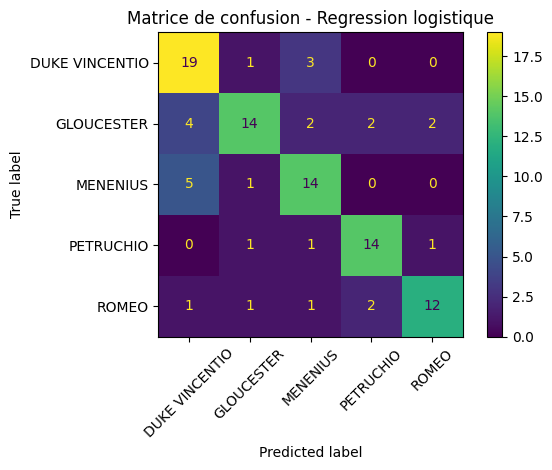

In [13]:
ConfusionMatrixDisplay.from_predictions(
    y_test, resultats[meilleur_modele], xticks_rotation=45
)
plt.title("Matrice de confusion - " + meilleur_modele)
plt.tight_layout()
plt.show()

### 8.3 Analyse des erreurs

On regarde les paires les plus confondues, quelques repliques mal classees, et
les termes qui pesent le plus pour chaque classe.

In [14]:
labels = sorted(donnees["locuteur"].unique())
matrice = confusion_matrix(y_test, resultats[meilleur_modele], labels=labels)

confusions = []
for i in range(len(labels)):
    for j in range(len(labels)):
        if i != j:
            confusions.append((matrice[i, j], labels[i], labels[j]))
confusions.sort(reverse=True)

print("paires les plus confondues :")
for compte, vrai, predit in confusions[:5]:
    print(vrai, "->", predit, ":", compte)

paires les plus confondues :
MENENIUS -> DUKE VINCENTIO : 5
GLOUCESTER -> DUKE VINCENTIO : 4
DUKE VINCENTIO -> MENENIUS : 3
ROMEO -> PETRUCHIO : 2
GLOUCESTER -> ROMEO : 2


In [15]:
pred_best = resultats[meilleur_modele]
X_test_liste = X_test.tolist()
y_test_liste = y_test.tolist()

print("repliques mal classees :")
compteur = 0
for i in range(len(y_test_liste)):
    if pred_best[i] != y_test_liste[i]:
        print("vrai :", y_test_liste[i], "| predit :", pred_best[i])
        print(X_test_liste[i][:200])
        print()
        compteur += 1
        if compteur == 5:
            break

repliques mal classees :
vrai : GLOUCESTER | predit : DUKE VINCENTIO
It is a quarrel most unnatural, To be revenged on him that loveth you.

vrai : DUKE VINCENTIO | predit : GLOUCESTER
Left her in her tears, and dried not one of them with his comfort; swallowed his vows whole, pretending in her discoveries of dishonour: in few, bestowed her on her own lamentation, which she yet wear

vrai : GLOUCESTER | predit : MENENIUS
He may command me as my sovereign; But you have power in me as in a kinsman.

vrai : GLOUCESTER | predit : DUKE VINCENTIO
Would you enforce me to a world of care? Well, call them again. I am not made of stone, But penetrable to your. kind entreats, Albeit against my conscience and my soul. Cousin of Buckingham, and you s

vrai : GLOUCESTER | predit : PETRUCHIO
I go; and if you plead as well for them As I can say nay to thee for myself, No doubt well bring it to a happy issue.



In [16]:
# Termes les plus discriminants d'un modele lineaire.
modele_lineaire = LogisticRegression(max_iter=1000, class_weight="balanced")
modele_lineaire.fit(Xtr, y_train)

termes = vectoriseur.get_feature_names_out()
for indice, classe in enumerate(modele_lineaire.classes_):
    poids = modele_lineaire.coef_[indice]
    meilleurs = np.argsort(poids)[-10:][::-1]
    print(classe, ":", termes[meilleurs].tolist())

DUKE VINCENTIO : ['your', 'angelo', 'duke', 'him', 'you', 'the duke', 'provost', 'sir', 'justice', 'to']
GLOUCESTER : ['king', 'clarence', 'brother', 'lord', 'the king', 'god', 'edward', 'his', 'cousin', 'warwick']
MENENIUS : ['marcius', 'you', 'you have', 'work', 'rome', 'he', 'tribunes', 'speak', 'gods', 'people']
PETRUCHIO : ['kate', 'her', 'and', 'father', 'not', 'sir', 'hortensio', 'knock', 'she', 'see']
ROMEO : ['love', 'thou', 'me', 'night', 'juliet', 'mercutio', 'that name', 'thee', 'doth', 'farewell']


**Analyse :**

- Les paires les plus confondues correspondent souvent a des personnages de la
  meme piece ou au registre proche, ou a une classe majoritaire qui attire les
  predictions.
- Plusieurs repliques mal classees sont ambigues : meme un lecteur humain
  hesiterait, ce qui fixe un plafond de performance.
- Si les termes les plus lourds contiennent des noms propres, le modele
  reconnait sans doute la piece plutot que le style du personnage. Ce n'est pas
  la meme tache.
- Le score est credible car le vocabulaire et l'IDF ont ete appris sur le train
  seulement : aucune information du test n'a pu remonter.

## 9. Pour aller plus loin

Validation croisee en 5 folds via un pipeline : la vectorisation est reajustee
dans chaque fold, ce qui rend la fuite de donnees structurellement impossible.
On regarde la dispersion, pas seulement la moyenne.

In [17]:
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2),
                              min_df=2, max_df=0.9, sublinear_tf=True)),
    ("modele", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

scores = cross_val_score(
    pipeline, donnees["replique"], donnees["locuteur"],
    cv=5, scoring="f1_macro",
)
print("scores :", scores.round(3).tolist())
print("moyenne :", round(scores.mean(), 3), "+/-", round(scores.std(), 3))

scores : [0.481, 0.575, 0.717, 0.535, 0.631]
moyenne : 0.588 +/- 0.081


## Rendu

Notebook execute, toutes les sorties visibles et toutes les cellules de reponse
remplies. Le bareme porte autant sur la justification des choix et l'analyse
des erreurs que sur le score obtenu.